# Vehicle Plates in Turkey — RF-DETR

## Install Required Libraries

In [1]:
# Install the required libraries
!pip install -q rfdetr>=1.4.0 supervision roboflow

## Import Required Libraries

In [2]:
# Import the necessary libraries
import os
from IPython.display import Image, display
import shutil
from google.colab import files, userdata
from roboflow import Roboflow
from rfdetr import RFDETRLarge
import supervision as sv
from supervision.metrics import MeanAveragePrecision
from tqdm import tqdm
from PIL import Image as PILImage

## Adding Created Custom Dataset From Roboflow To The Working Environment With API

In [3]:
# Authenticate with Roboflow and download the custom vehicle plates dataset in COCO format
os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
project = rf.workspace("vehicle-plate-detection-6l2v6").project("vehicle-plates-in-tr")
dataset = project.version(10).download("coco")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to vehicle-plates-in-tr-10 in coco:: 100%|██████████| 208/208 [00:00<00:00, 2373.53it/s]


## Train Custom Dataset 50 Epochs using RF-DETR Large Weights

In [4]:
# Train the RF-DETR Large model on the custom dataset for 50 epochs
model = RFDETRLarge()
model.train(dataset_dir=dataset.location, epochs=50, batch_size=4, grad_accum_steps=4)

[2026-03-07 14:44:03] [INFO] rf-detr - Downloading pretrained weights for rf-detr-large-2026.pth


rf-detr-large-2026.pth:   0%|          | 0.00/130M [00:00<?, ?iB/s]

[2026-03-07 14:44:07] [INFO] rf-detr - MD5 validation successful for rf-detr-large-2026.pth


[2026-03-07 14:44:07] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-03-07 14:44:07] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-03-07 14:44:09] [INFO] rf-detr - Loading pretrain weights


...

[2026-03-07 15:53:05] [INFO] rf-detr - Epoch: [47/50]  [ 0/10]  eta: 0:01:29  lr: 0.000100  class_error: 0.00  loss: 4.6189 (4.6189)  loss_ce: 0.4718 (0.4718)  loss_bbox: 0.0204 (0.0204)  loss_giou: 0.3663 (0.3663)  loss_ce_0: 0.5063 (0.5063)  loss_bbox_0: 0.0202 (0.0202)  loss_giou_0: 0.3825 (0.3825)  loss_ce_1: 0.4800 (0.4800)  loss_bbox_1: 0.0216 (0.0216)  loss_giou_1: 0.4011 (0.4011)  loss_ce_2: 0.4748 (0.4748)  loss_bbox_2: 0.0213 (0.0213)  loss_giou_2: 0.4000 (0.4000)  loss_ce_enc: 0.5663 (0.5663)  loss_bbox_enc: 0.0350 (0.0350)  loss_giou_enc: 0.4514 (0.4514)  loss_ce_unscaled: 0.4718 (0.4718)  class_error_unscaled: 0.0000 (0.0000)  loss_bbox_unscaled: 0.0041 (0.0041)  loss_giou_unscaled: 0.1831 (0.1831)  cardinality_error_unscaled: 3896.2500 (3896.2500)  loss_ce_0_unscaled: 0.5063 (0.5063)  loss_bbox_0_unscaled: 0.0040 (0.0040)  loss_giou_0_unscaled: 0.1912 (0.1912)  cardinality_error_0_unscaled: 3894.5000 (3894.5000)  loss_ce_1_unscaled: 0.4800 (0.4800)  loss_bbox_1_unscaled: 

[2026-03-07 15:54:31] [INFO] rf-detr - Epoch: [48/50]  [ 0/10]  eta: 0:01:07  lr: 0.000100  class_error: 0.00  loss: 4.0046 (4.0046)  loss_ce: 0.4246 (0.4246)  loss_bbox: 0.0211 (0.0211)  loss_giou: 0.3359 (0.3359)  loss_ce_0: 0.4496 (0.4496)  loss_bbox_0: 0.0219 (0.0219)  loss_giou_0: 0.3419 (0.3419)  loss_ce_1: 0.4233 (0.4233)  loss_bbox_1: 0.0224 (0.0224)  loss_giou_1: 0.3448 (0.3448)  loss_ce_2: 0.4176 (0.4176)  loss_bbox_2: 0.0208 (0.0208)  loss_giou_2: 0.3270 (0.3270)  loss_ce_enc: 0.4595 (0.4595)  loss_bbox_enc: 0.0270 (0.0270)  loss_giou_enc: 0.3671 (0.3671)  loss_ce_unscaled: 0.4246 (0.4246)  class_error_unscaled: 0.0000 (0.0000)  loss_bbox_unscaled: 0.0042 (0.0042)  loss_giou_unscaled: 0.1679 (0.1679)  cardinality_error_unscaled: 3893.5000 (3893.5000)  loss_ce_0_unscaled: 0.4496 (0.4496)  loss_bbox_0_unscaled: 0.0044 (0.0044)  loss_giou_0_unscaled: 0.1709 (0.1709)  cardinality_error_0_unscaled: 3896.7500 (3896.7500)  loss_ce_1_unscaled: 0.4233 (0.4233)  loss_bbox_1_unscaled: 

[2026-03-07 15:55:55] [INFO] rf-detr - Epoch: [49/50]  [ 0/10]  eta: 0:01:34  lr: 0.000100  class_error: 0.00  loss: 4.1688 (4.1688)  loss_ce: 0.4465 (0.4465)  loss_bbox: 0.0176 (0.0176)  loss_giou: 0.3461 (0.3461)  loss_ce_0: 0.4337 (0.4337)  loss_bbox_0: 0.0195 (0.0195)  loss_giou_0: 0.3847 (0.3847)  loss_ce_1: 0.4351 (0.4351)  loss_bbox_1: 0.0176 (0.0176)  loss_giou_1: 0.3537 (0.3537)  loss_ce_2: 0.4420 (0.4420)  loss_bbox_2: 0.0180 (0.0180)  loss_giou_2: 0.3605 (0.3605)  loss_ce_enc: 0.4454 (0.4454)  loss_bbox_enc: 0.0210 (0.0210)  loss_giou_enc: 0.4273 (0.4273)  loss_ce_unscaled: 0.4465 (0.4465)  class_error_unscaled: 0.0000 (0.0000)  loss_bbox_unscaled: 0.0035 (0.0035)  loss_giou_unscaled: 0.1731 (0.1731)  cardinality_error_unscaled: 3892.0000 (3892.0000)  loss_ce_0_unscaled: 0.4337 (0.4337)  loss_bbox_0_unscaled: 0.0039 (0.0039)  loss_giou_0_unscaled: 0.1924 (0.1924)  cardinality_error_0_unscaled: 3894.2500 (3894.2500)  loss_ce_1_unscaled: 0.4351 (0.4351)  loss_bbox_1_unscaled: 

[2026-03-07 15:57:30] [INFO] rf-detr - Epoch: [50/50]  [ 0/10]  eta: 0:01:39  lr: 0.000100  class_error: 0.00  loss: 3.7733 (3.7733)  loss_ce: 0.4072 (0.4072)  loss_bbox: 0.0155 (0.0155)  loss_giou: 0.3216 (0.3216)  loss_ce_0: 0.4155 (0.4155)  loss_bbox_0: 0.0161 (0.0161)  loss_giou_0: 0.3284 (0.3284)  loss_ce_1: 0.4141 (0.4141)  loss_bbox_1: 0.0163 (0.0163)  loss_giou_1: 0.3286 (0.3286)  loss_ce_2: 0.4098 (0.4098)  loss_bbox_2: 0.0158 (0.0158)  loss_giou_2: 0.3250 (0.3250)  loss_ce_enc: 0.4131 (0.4131)  loss_bbox_enc: 0.0199 (0.0199)  loss_giou_enc: 0.3262 (0.3262)  loss_ce_unscaled: 0.4072 (0.4072)  class_error_unscaled: 0.0000 (0.0000)  loss_bbox_unscaled: 0.0031 (0.0031)  loss_giou_unscaled: 0.1608 (0.1608)  cardinality_error_unscaled: 3891.2500 (3891.2500)  loss_ce_0_unscaled: 0.4155 (0.4155)  loss_bbox_0_unscaled: 0.0032 (0.0032)  loss_giou_0_unscaled: 0.1642 (0.1642)  cardinality_error_0_unscaled: 3872.2500 (3872.2500)  loss_ce_1_unscaled: 0.4141 (0.4141)  loss_bbox_1_unscaled: 

[2026-03-07 15:58:40] [INFO] rf-detr - Epoch: [50/50]  [ 9/10]  eta: 0:00:07  lr: 0.000100  class_error: 0.00  loss: 3.6274 (3.7855)  loss_ce: 0.3687 (0.3992)  loss_bbox: 0.0156 (0.0168)  loss_giou: 0.2848 (0.3094)  loss_ce_0: 0.4145 (0.4212)  loss_bbox_0: 0.0176 (0.0187)  loss_giou_0: 0.3235 (0.3324)  loss_ce_1: 0.3908 (0.4097)  loss_bbox_1: 0.0174 (0.0182)  loss_giou_1: 0.3077 (0.3238)  loss_ce_2: 0.3766 (0.4042)  loss_bbox_2: 0.0165 (0.0174)  loss_giou_2: 0.2958 (0.3183)  loss_ce_enc: 0.4131 (0.4305)  loss_bbox_enc: 0.0210 (0.0212)  loss_giou_enc: 0.3262 (0.3445)  loss_ce_unscaled: 0.3687 (0.3992)  class_error_unscaled: 0.0000 (-0.0000)  loss_bbox_unscaled: 0.0031 (0.0034)  loss_giou_unscaled: 0.1424 (0.1547)  cardinality_error_unscaled: 3894.2500 (3893.8750)  loss_ce_0_unscaled: 0.4145 (0.4212)  loss_bbox_0_unscaled: 0.0035 (0.0037)  loss_giou_0_unscaled: 0.1617 (0.1662)  cardinality_error_0_unscaled: 3892.2500 (3888.9500)  loss_ce_1_unscaled: 0.3908 (0.4097)  loss_bbox_1_unscaled:

## Model Training & Validation Visualizing Losses and Success Metrics

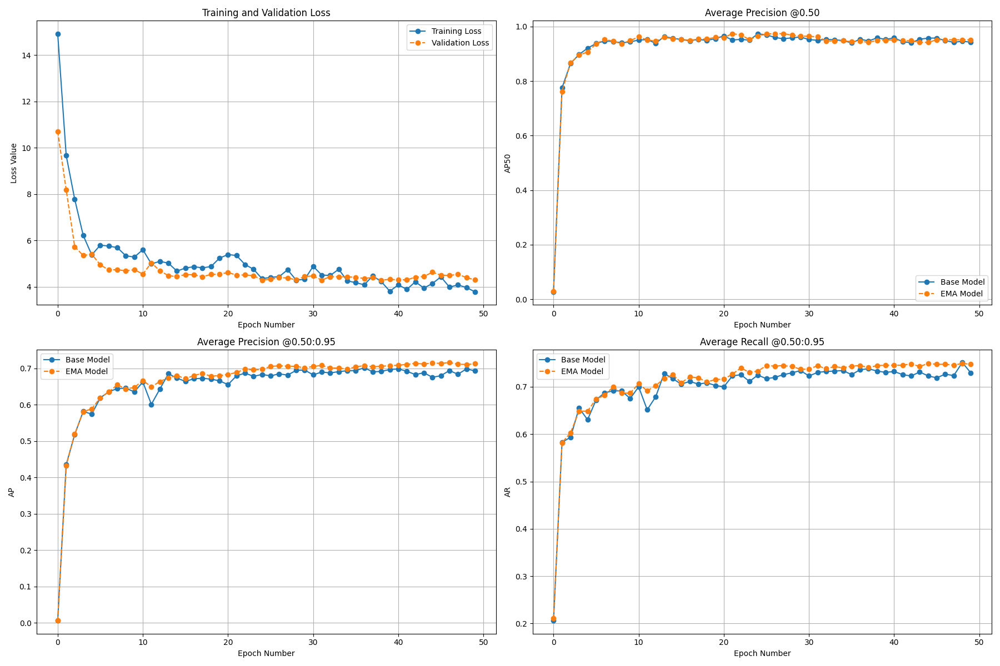

In [5]:
# Display the training and validation loss and success metrics plot
display(Image("/content/output/metrics_plot.png"))

## Architecture Of The Best Trained Model

In [6]:
# Load the best trained weights, optimize for inference, and print the model architecture
model = RFDETRLarge(pretrain_weights="/content/output/checkpoint_best_total.pth")
model.optimize_for_inference()
print(model)

[2026-03-07 15:59:20] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-03-07 15:59:20] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-03-07 15:59:21] [INFO] rf-detr - Loading pretrain weights


[2026-03-07 15:59:21] [WARNING] rf-detr - Reinitializing detection head with 2 classes based on pretrained weights, configured for 90.
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


## Processing The Best Trained Model On Any Image In The Test Set In The Dataset

In [7]:
# Load the test set and collect ground-truth targets and model predictions
ds = sv.DetectionDataset.from_coco(
    images_directory_path=f"{dataset.location}/test",
    annotations_path=f"{dataset.location}/test/_annotations.coco.json",
)

targets     = []
predictions = []

# Run inference on every test image and store its targets and predictions
for path, image, annotations in tqdm(ds):
    img       = PILImage.open(path)
    detections = model.predict(img, threshold=0)
    targets.append(annotations)
    predictions.append(detections)

100%|██████████| 10/10 [00:02<00:00,  3.88it/s]


## Evaluation — Mean Average Precision (mAP) on Test Set

In [8]:
# Compute the mean Average Precision (mAP) over the test set
map_metric = MeanAveragePrecision()
map_result  = map_metric.update(predictions, targets).compute()
print(map_result)

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.746
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.997
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.958
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.735
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.844
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = -1.000


## Visualization Of The Best Trained Model On The Rendered Images

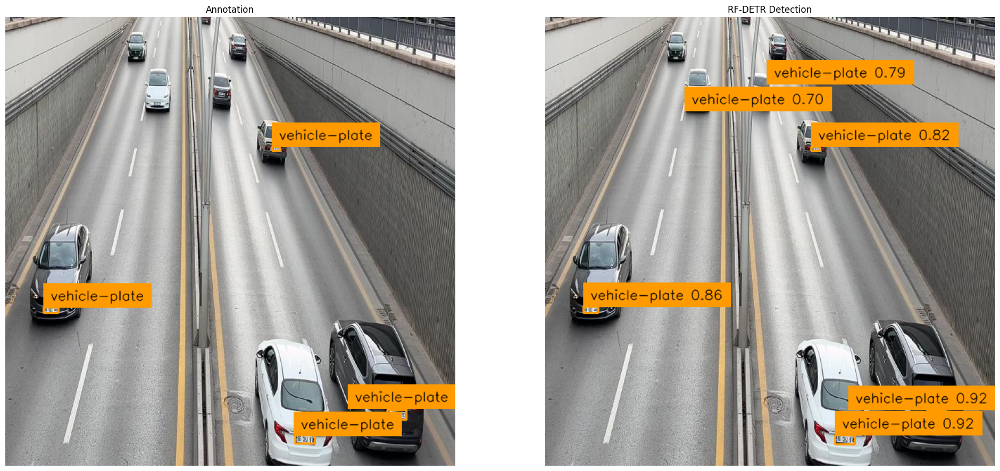

Image 1/10 — Detected: 6 object(s)
  1. vehicle-plate: 92.35%
  2. vehicle-plate: 92.04%
  3. vehicle-plate: 86.24%
  4. vehicle-plate: 81.63%
  5. vehicle-plate: 78.69%
  6. vehicle-plate: 70.45%


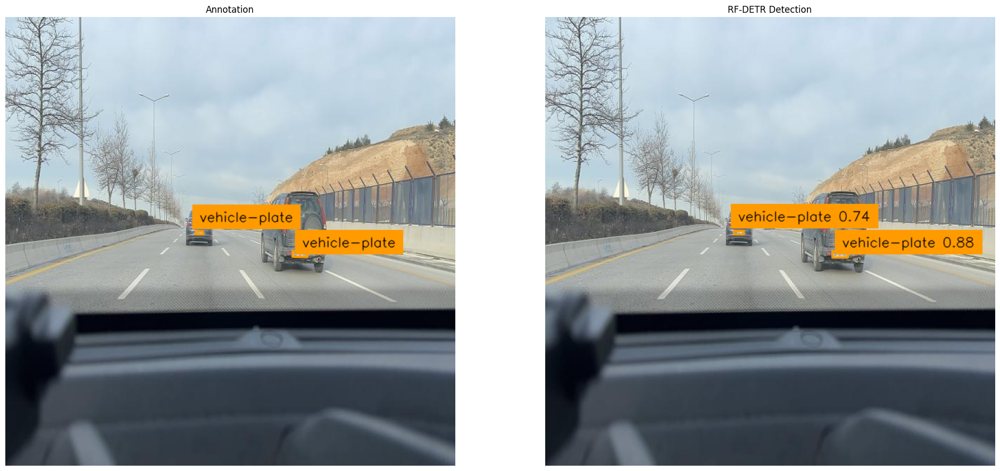

Image 2/10 — Detected: 2 object(s)
  1. vehicle-plate: 88.34%
  2. vehicle-plate: 73.67%


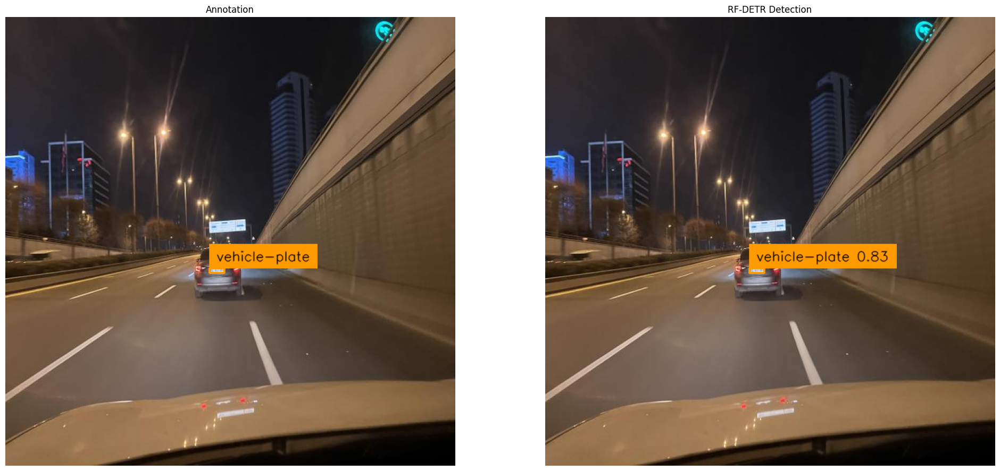

Image 3/10 — Detected: 1 object(s)
  1. vehicle-plate: 83.47%


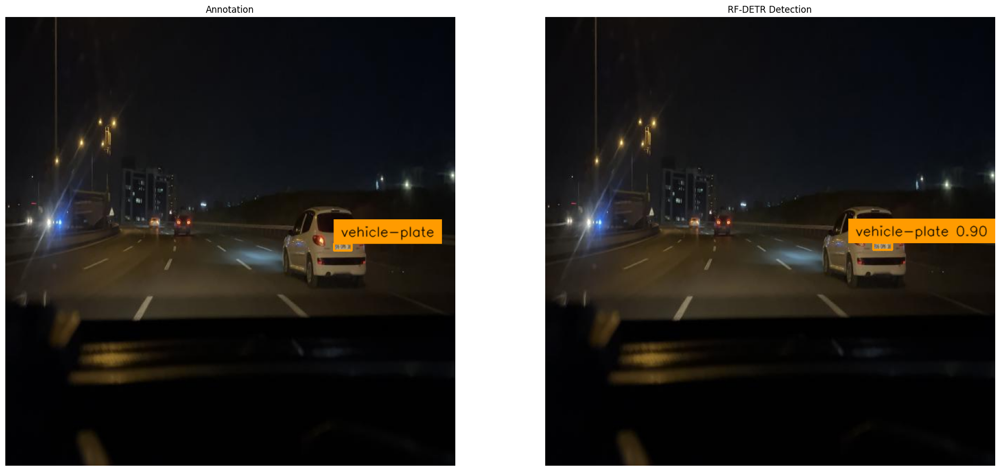

Image 4/10 — Detected: 1 object(s)
  1. vehicle-plate: 90.17%


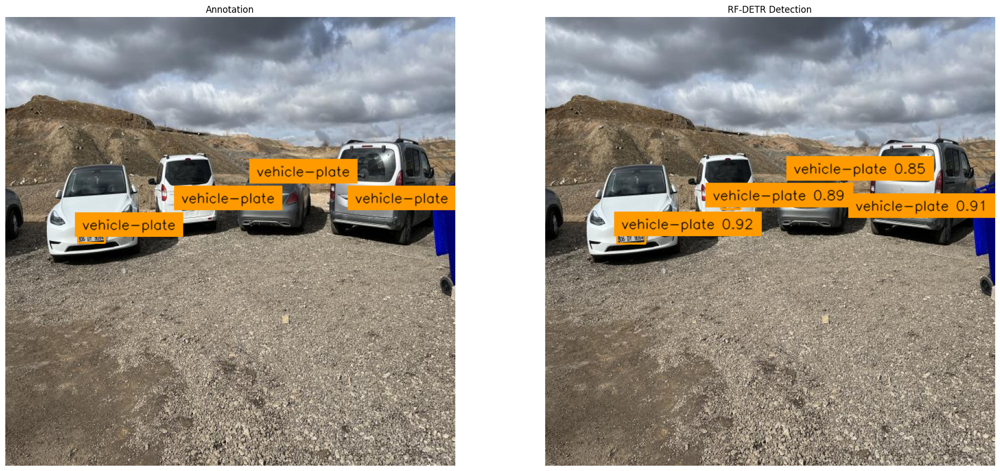

Image 5/10 — Detected: 4 object(s)
  1. vehicle-plate: 91.59%
  2. vehicle-plate: 91.39%
  3. vehicle-plate: 89.45%
  4. vehicle-plate: 84.98%


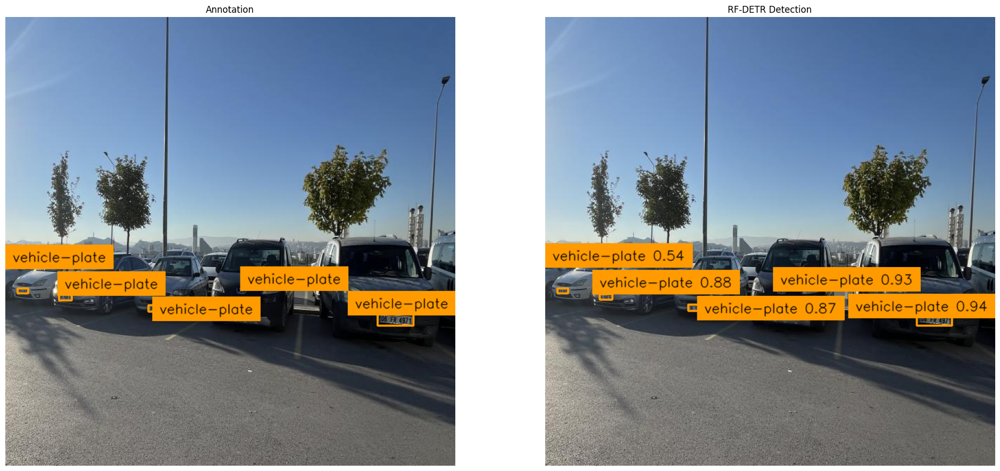

Image 6/10 — Detected: 5 object(s)
  1. vehicle-plate: 93.52%
  2. vehicle-plate: 93.04%
  3. vehicle-plate: 87.76%
  4. vehicle-plate: 87.31%
  5. vehicle-plate: 54.00%


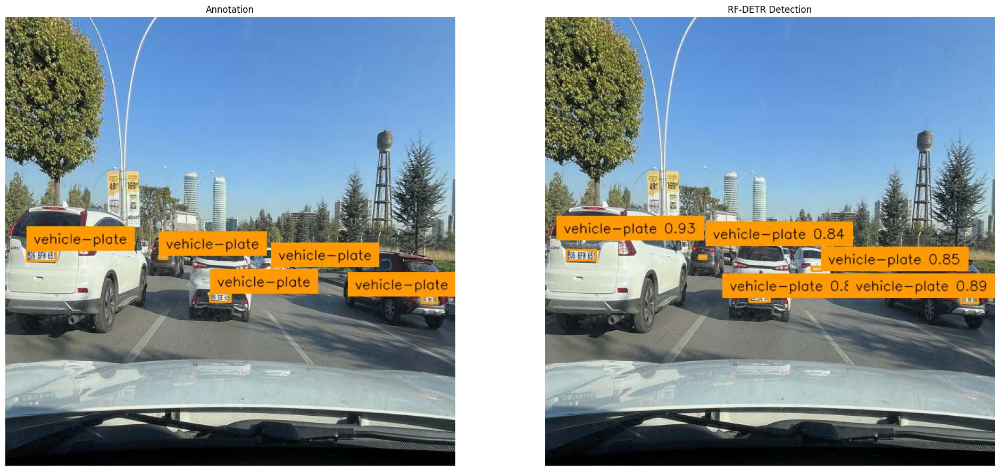

Image 7/10 — Detected: 5 object(s)
  1. vehicle-plate: 92.79%
  2. vehicle-plate: 89.39%
  3. vehicle-plate: 89.01%
  4. vehicle-plate: 85.49%
  5. vehicle-plate: 84.08%


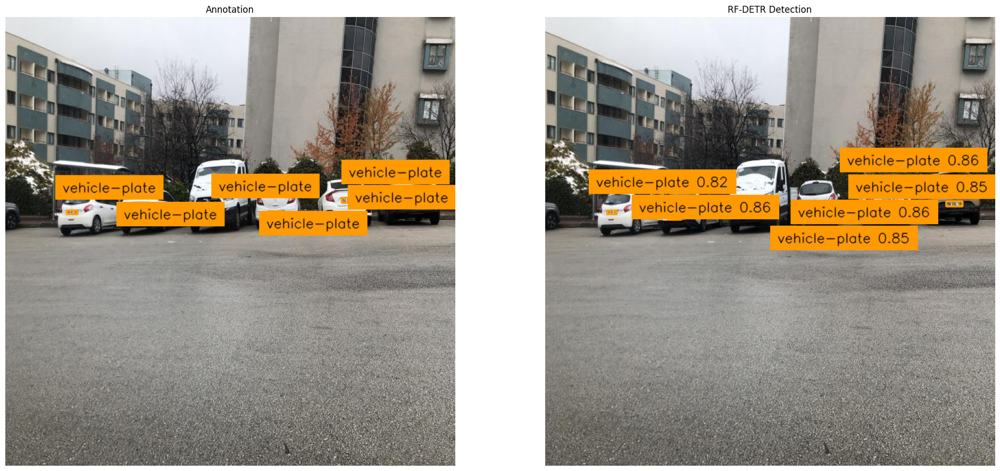

Image 8/10 — Detected: 6 object(s)
  1. vehicle-plate: 85.89%
  2. vehicle-plate: 85.81%
  3. vehicle-plate: 85.76%
  4. vehicle-plate: 85.18%
  5. vehicle-plate: 84.92%
  6. vehicle-plate: 81.96%


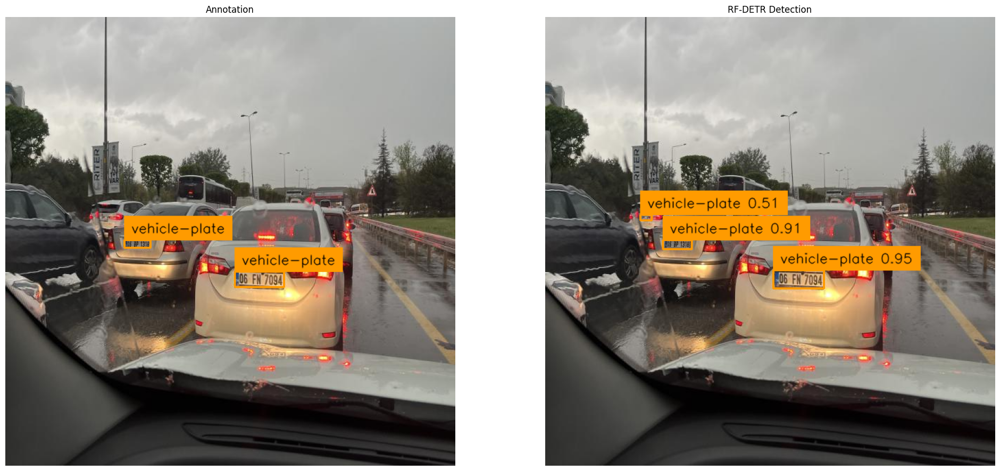

Image 9/10 — Detected: 3 object(s)
  1. vehicle-plate: 95.06%
  2. vehicle-plate: 90.59%
  3. vehicle-plate: 50.56%


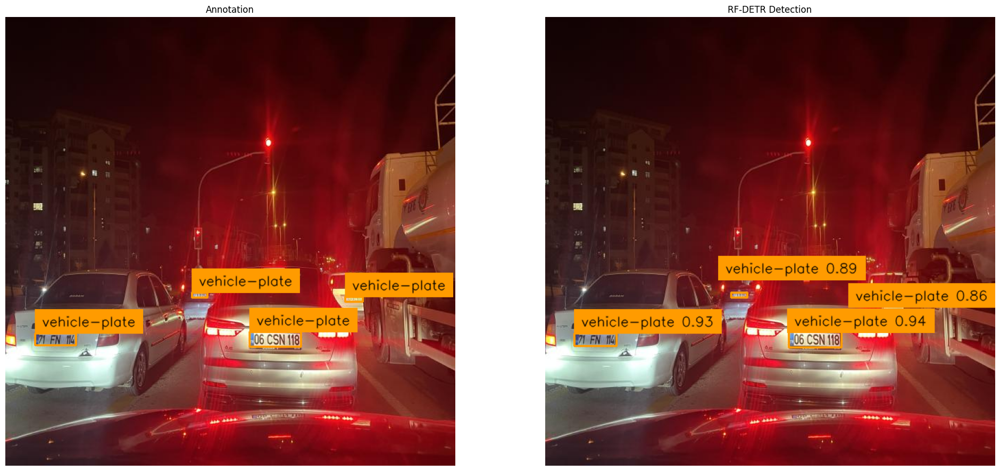

Image 10/10 — Detected: 4 object(s)
  1. vehicle-plate: 94.23%
  2. vehicle-plate: 92.97%
  3. vehicle-plate: 88.85%
  4. vehicle-plate: 85.55%


In [9]:
# Define a color palette for drawing the detections
COLOR_PALETTE = sv.ColorPalette.from_hex([
    "#ffff00", "#ff9b00", "#ff8080", "#ff66b2", "#ff66ff",
    "#b266ff", "#9999ff", "#3399ff", "#66ffff", "#33ff99",
    "#66ff66", "#99ff00"
])

# Compare ground-truth annotations with RF-DETR detections on each test image
for idx in range(len(ds)):
    path, image, annotations = ds[idx]
    img = PILImage.open(path)

    detections = model.predict(img, threshold=0.5)

    text_scale = sv.calculate_optimal_text_scale(resolution_wh=img.size)
    thickness  = sv.calculate_optimal_line_thickness(resolution_wh=img.size)

    bbox_annotator  = sv.BoxAnnotator(color=COLOR_PALETTE, thickness=thickness)
    label_annotator = sv.LabelAnnotator(
        color=COLOR_PALETTE,
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    gt_labels   = [ds.classes[c] for c in annotations.class_id]
    pred_labels = [
        f"{ds.classes[c]} {conf:.2f}"
        for c, conf in zip(detections.class_id, detections.confidence)
    ]

    gt_img   = bbox_annotator.annotate(img.copy(), annotations)
    gt_img   = label_annotator.annotate(gt_img, annotations, gt_labels)
    pred_img = bbox_annotator.annotate(img.copy(), detections)
    pred_img = label_annotator.annotate(pred_img, detections, pred_labels)

    sv.plot_images_grid(
        images=[gt_img, pred_img],
        grid_size=(1, 2),
        titles=["Annotation", "RF-DETR Detection"],
        size=(24, 12)
    )

    print(f"Image {idx + 1}/{len(ds)} — Detected: {len(detections)} object(s)")
    for i, (c, conf) in enumerate(zip(detections.class_id, detections.confidence)):
        print(f"  {i + 1}. {ds.classes[c]}: {conf:.2%}")

## Save and Download Training and Validation Outputs Created with Custom Dataset

In [10]:
# Archive the training and validation outputs and download them as a zip file
output_dir = '/content/output'
output_zip = '/content/output.zip'

shutil.make_archive(base_name='/content/output', format='zip', root_dir=output_dir)
files.download(output_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>